# Delhi Bus Journey Planner: travel times learned from GPS data

A bus journey planner for Delhi that uses **observed** bus travel times instead of the published timetable.

**Data**
- DTC bus GPS pings for October 2026 (a GTFS-realtime feed archived as one SQLite file per day)
- Static GTFS schedule for Delhi buses (stops, routes, trips, stop times)

**Pipeline**
1. Download the GPS archive and extract the days used (3 for training, 1 held out for validation)
2. Understand how GPS trip IDs relate to GTFS trip IDs
3. Clean the GPS pings (Delhi bounding box, de-duplication, GPS spike removal)
4. Map-match each trip's pings to its scheduled stops, giving observed stop-to-stop travel times
5. Learn median travel times per stop pair, day type (weekday / weekend) and hour of day
6. Build the journey planner: time-dependent Dijkstra over route-stops, with walking transfers and a waiting-time model
7. Evaluate against the timetable on a held-out day, and against Google Maps on a small set of journeys
8. Serve the planner as a REST API with a click-on-the-map web page

**Before you run**
- Run on Google Colab: the notebook uses `/content`, `google.colab.files` for the GTFS upload, and a Cloudflare tunnel for the public link.
- You need about 30 GB of free disk (15 GB archive plus 13.4 GB of extracted daily databases).
- Step 1 asks you to upload the static GTFS zip (`delhi_buses_static_gtfs_v1.zip`).
- Cleaning and segmentation skip days that were already processed, so re-running after a disconnect is cheaper.

In [ ]:
# System tools and Python packages
!apt-get -qq install -y aria2 p7zip-full
!pip -q install fastapi uvicorn nest_asyncio

In [ ]:
import os, re, glob, math, heapq, json, time, sqlite3, subprocess, threading, zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.spatial import cKDTree

# ---- configuration -----------------------------------------------------------------
DATA_URL = "https://pub-091bd9e794bb4877b10b29e6df80f065.r2.dev/2026-10/delhi-dtc-bus-gtfs-rt-2026-10.7z"
ARCHIVE = "/content/data.7z"

DAYS       = ["07", "08", "11", "14"]    # October 2026: Wed, Thu, Sun, Wed
TRAIN_DAYS = ["07", "08", "11"]          # used to fit the travel-time model
VALID_DAY  = "14"                        # held out: never used to fit the model
DAYTYPE    = {"07": "wd", "08": "wd", "11": "we", "14": "wd"}   # weekday / weekend

MAXD = 120                               # metres: a ping this close to a stop counts as "at the stop"
DELHI_LAT, DELHI_LNG = (28.2, 29.1), (76.7, 77.8)   # bounding box used to drop bad GPS fixes
IST = 19800                              # UTC+5:30 in seconds

CLEAN_DIR, SEG_DIR, MODEL_DIR, OUT_DIR = "/content/clean", "/content/seg", "/content/model", "/content/outputs"
for d in (CLEAN_DIR, SEG_DIR, MODEL_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

## 1. Data

The archive holds one SQLite database per day (31 days, about 15 GB compressed). Only four days are extracted: three weekday/weekend days for training and one weekday held out for validation.

In [ ]:
!aria2c -x 16 -s 16 -k 1M -c --summary-interval=0 --console-log-level=warn -d /content -o data.7z "{DATA_URL}"
!ls -lh {ARCHIVE}

Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
ad4e54|OK  |    94MiB/s|/content/data.7z

Status Legend:
(OK):download completed.
-rw-r--r-- 1 root root 15G Nov 22 16:28 /content/data.7z


In [ ]:
!7z l {ARCHIVE} | grep bus_movements

2026-10-01 18:30:05 ....A   3420090368    467018574  bus_movements_2026_10_01.db
2026-10-02 18:29:59 ....A   3204751360    448757283  bus_movements_2026_10_02.db
2026-10-03 18:30:03 ....A   3450224640    479907099  bus_movements_2026_10_03.db
2026-10-04 18:30:07 ....A   3306258432    465294074  bus_movements_2026_10_04.db
2026-10-05 18:30:01 ....A   3428802560    448206273  bus_movements_2026_10_05.db
2026-10-06 18:30:05 ....A   3374170112    457564908  bus_movements_2026_10_06.db
2026-10-07 14:21:50 ....A   2796498944    381903738  bus_movements_2026_10_07.db
2026-10-08 18:30:09 ....A   3308322816    456915647  bus_movements_2026_10_08.db
2026-10-09 18:30:03 ....A   3225186304    425154424  bus_movements_2026_10_09.db
2026-10-10 18:30:08 ....A   2934251520    405277656  bus_movements_2026_10_10.db
2026-10-11 18:30:02 ....A   2870554624    394348822  bus_movements_2026_10_11.db
2026-10-12 18:30:07 ....A   2871775232    394693960  bus_movements_2026_10_12.db
2026-10-13 18:30:07 ....A   

In [ ]:
files_to_extract = " ".join(f"bus_movements_2026_10_{d}.db" for d in DAYS)
!cd /content && 7z x -y -bso0 -bsp0 data.7z {files_to_extract}
!ls -lh /content/*.db

-rw-r--r-- 1 root root 2.7G Oct  7 14:21 /content/bus_movements_2026_10_07.db
-rw-r--r-- 1 root root 3.1G Oct  8 18:30 /content/bus_movements_2026_10_08.db
-rw-r--r-- 1 root root 2.7G Oct 11 18:30 /content/bus_movements_2026_10_11.db
-rw-r--r-- 1 root root 4.2G Oct 14 18:29 /content/bus_movements_2026_10_14.db


The static GTFS schedule is not part of the archive. Upload `delhi_buses_static_gtfs_v1.zip` when prompted.

In [ ]:
GTFS_DIR = "/content/gtfs"
if not glob.glob(f"{GTFS_DIR}/**/stops.txt", recursive=True):
    from google.colab import files
    up = files.upload()                                   # choose delhi_buses_static_gtfs_v1.zip
    gtfs_zip = list(up.keys())[0]
    os.makedirs(GTFS_DIR, exist_ok=True)
    subprocess.run(["unzip", "-o", "-q", f"/content/{gtfs_zip}", "-d", GTFS_DIR], check=True)

G = os.path.dirname(glob.glob(f"{GTFS_DIR}/**/stops.txt", recursive=True)[0])

## 2. Data understanding

### 2.1 The static GTFS schedule

In [ ]:
stops  = pd.read_csv(f"{G}/stops.txt",  dtype={"stop_id": str})
routes = pd.read_csv(f"{G}/routes.txt", dtype={"route_id": str})
trips  = pd.read_csv(f"{G}/trips.txt",  dtype={"trip_id": str, "route_id": str})
print("GTFS folder:", G)
print(len(stops), "stops |", len(routes), "routes |", len(trips), "trips")

for name, df in [("stops", stops), ("routes", routes), ("trips", trips)]:
    print(f"\n--- {name} columns: {list(df.columns)}")
    print(df.head(3).to_string())

print("\nshapes.txt present:", os.path.exists(f"{G}/shapes.txt"))
print("stop_times.txt present:", os.path.exists(f"{G}/stop_times.txt"))

GTFS folder: /content/gtfs
6862 stops | 2574 routes | 80357 trips

--- stops columns: ['stop_id', 'stop_code', 'stop_name', 'stop_lat', 'stop_lon']
   stop_id stop_code               stop_name   stop_lat   stop_lon
0        1  9CE15308  Rohini Sec 22 Terminal  28.717971  77.063900
1        2  49FEABBE         Lakhhi Ram Park  28.713533  77.060302
2     4470  211FB561              Aman Vihar  28.711313  77.063228

--- routes columns: ['agency_id', 'route_id', 'route_long_name', 'route_short_name', 'route_desc', 'route_type']
  agency_id  route_id route_long_name route_short_name                                               route_desc  route_type
0     DIMTS         1        102ADOWN         102ADOWN               Rohini Sec 22 Terminal to Azadpur Terminal           3
1     DIMTS         4          102AUP           102AUP               Azadpur Terminal to Rohini Sec 22 Terminal           3
2     DIMTS         5         102DOWN          102DOWN  Rohini Sec 22 Terminal to Old Delhi Railwa

### 2.2 The GPS feed (one day, 8 Oct)

In [ ]:
con = sqlite3.connect("/content/bus_movements_2026_10_08.db")

print(pd.read_sql("SELECT * FROM vehicle_feed LIMIT 5", con).to_string())
print(pd.read_sql("""
    SELECT COUNT(*) AS rows_total,
           COUNT(DISTINCT vehicle_id) AS buses,
           COUNT(DISTINCT route_id)   AS routes,
           COUNT(trip_id)             AS rows_with_trip_id,
           COUNT(DISTINCT trip_id)    AS distinct_trips
    FROM vehicle_feed
""", con).to_string())

gps_trips  = pd.read_sql("SELECT DISTINCT trip_id FROM vehicle_feed WHERE trip_id IS NOT NULL", con)["trip_id"].astype(str)
gps_routes = pd.read_sql("SELECT DISTINCT CAST(route_id AS INT) AS r FROM vehicle_feed WHERE route_id IS NOT NULL", con)["r"].astype(str)

print("\nGPS trip_id examples:", gps_trips.head(3).tolist())
print("GTFS trip_id examples:", trips["trip_id"].astype(str).head(3).tolist())
print("trip_id match rate :", round(gps_trips.isin(trips["trip_id"].astype(str)).mean(), 3))
print("route_id match rate:", round(gps_routes.isin(routes["route_id"].astype(str)).mean(), 3))
con.close()

   vehicle_id               lat               lng      speed  route_id          trip_id   timestamp        date      time
0  DL51EV9801  28.6112174987793  77.2120513916016   1.968483    2106.0       2106_02_10  1791406908  2026-10-08  02:31:56
1  DL51EV9606  28.6347885131836  77.2174606323242   2.657923    2105.0       2105_02_05  1791406908  2026-10-08  02:31:56
2  DL51EV9755  28.6255187988281  77.0655136108398  14.128153    1486.0       1486_01_25  1791406908  2026-10-08  02:31:56
3  DL51GD9624  28.6460208892822  77.3151931762695  16.697149    1484.0  1484_01_51_6317  1791406907  2026-10-08  02:31:56
4  DL51EV1759  28.6741237640381  77.2433166503906   2.645929    1497.0  1497_01_44_2325  1791406907  2026-10-08  02:31:56
   rows_total  buses  routes  rows_with_trip_id  distinct_trips
0    30213919   6238    2161           30213919           82125

GPS trip_id examples: ['2106_02_10', '2105_02_05', '1486_01_25']
GTFS trip_id examples: ['1000_FULL_06_10', '1000_FULL_07_50', '1000_FULL_1

### 2.3 Linking GPS trips to GTFS trips

GPS trip IDs never equal GTFS trip IDs exactly. GTFS IDs look like `1000_FULL_06_10` (route, FULL/SHORT variant, scheduled start hour and minute). GPS IDs come in two shapes: `route_hh_mm`, which lines up with the GTFS start time, and `route_hh_mm_suffix`, which carries an extra numeric suffix. The next two cells measure how well each shape can be linked to the schedule.

In [ ]:
import re

print("trips.txt columns:", list(trips.columns))
print("\nGTFS trip_id shapes:")
print(trips["trip_id"].astype(str).str.replace(r"\d+", "#", regex=True).value_counts().head(8))
print("\nGPS trip_id shapes:")
print(gps_trips.str.replace(r"\d+", "#", regex=True).value_counts().head(8))

def gtfs_key(t):
    m = re.match(r"^(\d+)_[A-Za-z]+_(\d{2})_(\d{2})", t)
    return f"{m.group(1)}_{m.group(2)}_{m.group(3)}" if m else None

def gps_key(t):
    m = re.match(r"^(\d+)_(\d{2})_(\d{2})", t)
    return f"{m.group(1)}_{m.group(2)}_{m.group(3)}" if m else None

gtfs_keys = set(trips["trip_id"].astype(str).map(gtfs_key).dropna())
gps_k = gps_trips.map(gps_key).dropna()
print("\nGPS trips parsed:", len(gps_k), "of", len(gps_trips))
print("Key match rate  :", round(gps_k.isin(gtfs_keys).mean(), 3))
print("Unmatched examples:", gps_k[~gps_k.isin(gtfs_keys)].head(8).tolist())
print("GTFS key examples :", sorted(gtfs_keys)[:5])

print("\nstop_times.txt columns:")
print(pd.read_csv(f"{G}/stop_times.txt", nrows=3).to_string())
print("\nshapes.txt present:", os.path.exists(f"{G}/shapes.txt"))

trips.txt columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'trip_short_name', 'direction_id', 'block_id', 'shape_id', 'wheelchair_accessible', 'bikes_allowed']

GTFS trip_id shapes:
trip_id
#_FULL_#_#     69224
#_SHORT_#_#    11133
Name: count, dtype: int64

GPS trip_id shapes:
trip_id
#_#_#_#    42966
#_#_#      39159
Name: count, dtype: int64

GPS trips parsed: 82125 of 82125
Key match rate  : 0.49
Unmatched examples: ['1484_01_51', '1497_01_44', '1498_00_49', '1485_02_05', '2105_02_15', '1498_02_18', '1498_02_30', '1483_02_12']
GTFS key examples : ['1000_06_10', '1000_07_50', '1000_11_05', '1000_12_45', '1000_15_10']

stop_times.txt columns:
        trip_id arrival_time departure_time  stop_id  stop_sequence  fare_stage  stop_dist
0  1_FULL_06_05     06:05:00       06:05:00        1              0           0        NaN
1  1_FULL_06_05     06:07:00       06:07:00        2              1           0        NaN
2  1_FULL_06_05     06:08:16       06:08:16     4470       

In [ ]:
import numpy as np
from collections import defaultdict

gps_df = pd.DataFrame({"trip_id": gps_trips.values})
gps_df["has_suffix"] = gps_df.trip_id.str.count("_") == 3
gps_df["key"]   = gps_df.trip_id.map(gps_key)
gps_df["route"] = gps_df.trip_id.str.split("_").str[0]
gps_df["match"] = gps_df.key.isin(gtfs_keys)

print("Match rate by id type (has_suffix=True means 4-part ids):")
print(gps_df.groupby("has_suffix")["match"].agg(["mean", "size"]))

trips["rt_prefix"] = trips.trip_id.astype(str).str.split("_").str[0]
print("\nGTFS trip_id prefix equals route_id:", round((trips.rt_prefix == trips.route_id.astype(str)).mean(), 3))

um = gps_df[~gps_df.match]
print("Unmatched trips:", len(um))
print("  share with suffix            :", round(um.has_suffix.mean(), 3))
print("  route prefix exists in GTFS  :", round(um.route.isin(set(trips.rt_prefix)).mean(), 3))
print("  unmatched routes (top 10)    :", um.route.value_counts().head(10).to_dict())

# For unmatched trips on routes GTFS knows: how far is the nearest scheduled start?
starts = defaultdict(list)
for k in gtfs_keys:
    r, h, m = k.split("_")
    starts[r].append(int(h) * 60 + int(m))
starts = {r: np.array(v) for r, v in starts.items()}

def nearest_diff(k):
    r, h, m = k.split("_")
    a = starts.get(r)
    return np.nan if a is None else np.abs(a - (int(h) * 60 + int(m))).min()

samp = um.sample(min(3000, len(um)), random_state=0).copy()
samp["diff_min"] = samp.key.map(nearest_diff)
print("\nMinutes to nearest scheduled start (unmatched sample):")
print(samp.diff_min.describe())
print("within 5 min :", round((samp.diff_min <= 5).mean(), 3))
print("within 15 min:", round((samp.diff_min <= 15).mean(), 3))
print(samp[["trip_id", "diff_min"]].head(10).to_string())

Match rate by id type (has_suffix=True means 4-part ids):
                mean   size
has_suffix                 
False       0.956332  39159
True        0.064726  42966

GTFS trip_id prefix equals route_id: 1.0
Unmatched trips: 41895
  share with suffix            : 0.959
  route prefix exists in GTFS  : 0.995
  unmatched routes (top 10)    : {'1616': 252, '1615': 246, '2251': 214, '868': 194, '2232': 171, '1924': 164, '1900': 152, '2031': 151, '2229': 148, '2066': 148}

Minutes to nearest scheduled start (unmatched sample):
count    2987.000000
mean       33.527954
std        82.706573
min         1.000000
25%         2.000000
50%         5.000000
75%        20.000000
max      1061.000000
Name: diff_min, dtype: float64
within 5 min : 0.526
within 15 min: 0.697
               trip_id  diff_min
40914    32_14_11_2184      29.0
71854  3678_20_58_1490       2.0
44884  1653_15_00_9348      40.0
25900  1011_10_52_2306      42.0
72831  2540_21_12_4315       2.0
63069    194_18_59_412       

**Finding.** The 3-part IDs match the schedule 95.6% of the time. The 4-part IDs match only 6.5% of the time, and for unmatched trips the nearest scheduled start on the same route is a median of 5 minutes away, so a specific scheduled trip (and therefore a stop sequence) cannot be assigned reliably. Only 3-part GPS trips that exist in GTFS are used from here on (37,449 of the 82,125 distinct trips on 8 Oct, about 46%). For those trips the stop sequence is known, so pings can be tied to stops.

## 3. Cleaning the GPS pings

For each day, keep only pings of linkable trips (3-part IDs found in GTFS) that fall inside the Delhi bounding box, then:
- drop duplicate `(trip, timestamp)` pings and sort by trip and time
- drop **spikes**: a ping is removed if both the jump from the previous ping and the jump to the next ping imply a speed above 28 m/s (about 100 km/h)

The result is one compact parquet file per day.

In [ ]:
keys_sorted = sorted(gtfs_keys)                        # GTFS trip "keys": route_hh_mm
code_map = {k: i for i, k in enumerate(keys_sorted)}   # key -> small integer (saves memory)


def process_day(day):
    """Raw pings of one day -> clean parquet with columns trip_code, ts, lat, lng, speed."""
    out = f"{CLEAN_DIR}/day_{day}.parquet"
    if os.path.exists(out):
        print(day, "already done")
        return
    con = sqlite3.connect(f"/content/bus_movements_2026_10_{day}.db")
    q = """SELECT trip_id, CAST(lat AS REAL) AS lat, CAST(lng AS REAL) AS lng,
                  speed, CAST(timestamp AS INTEGER) AS ts
           FROM vehicle_feed
           WHERE (length(trip_id) - length(replace(trip_id,'_',''))) = 2"""   # 3-part ids only
    parts, n_read = [], 0
    for ch in pd.read_sql(q, con, chunksize=2_000_000):
        n_read += len(ch)
        ch = ch[ch.lat.between(*DELHI_LAT) & ch.lng.between(*DELHI_LNG)]
        ch = ch[ch.trip_id.isin(gtfs_keys)].copy()
        ch["trip_code"] = ch.trip_id.map(code_map).astype("int32")
        ch = ch[["trip_code", "ts", "lat", "lng", "speed"]].astype(
            {"ts": "int32", "lat": "float32", "lng": "float32", "speed": "float32"})
        parts.append(ch)
    con.close()
    df = pd.concat(parts, ignore_index=True)
    del parts
    df = df.drop_duplicates(["trip_code", "ts"]).sort_values(["trip_code", "ts"]).reset_index(drop=True)

    # spike filter: drop points with an impossible jump both from the previous and to the next ping
    tid = df.trip_code.values
    lat = df.lat.values.astype("float64"); lng = df.lng.values.astype("float64"); ts = df.ts.values.astype("int64")
    same = np.r_[False, tid[1:] == tid[:-1]]
    dy = np.r_[0.0, np.diff(lat)] * 110540
    dx = np.r_[0.0, np.diff(lng)] * 111320 * np.cos(np.radians(lat))
    dt = np.r_[0, np.diff(ts)]
    v = np.where(same & (dt > 0), np.hypot(dx, dy) / np.maximum(dt, 1), 0.0)
    spike = (v > 28) & (np.r_[v[1:], 0.0] > 28)
    n_spike = int(spike.sum())
    df = df[~spike].reset_index(drop=True)

    df.to_parquet(out)
    print(f"{day}: read {n_read:,} 3-part rows -> kept {len(df):,} | spikes removed {n_spike:,} | "
          f"trips {df.trip_code.nunique():,} | median pings/trip {int(df.groupby('trip_code').size().median())} | "
          f"file {os.path.getsize(out)/1e6:.0f} MB")


for d in DAYS:
    process_day(d)

07: read 12,671,214 3-part rows -> kept 7,803,208 | spikes removed 462 | trips 32,667 | median pings/trip 195 | file 92 MB
08: read 16,084,482 3-part rows -> kept 9,919,206 | spikes removed 593 | trips 37,449 | median pings/trip 219 | file 117 MB
11: read 4,136,500 3-part rows -> kept 2,676,090 | spikes removed 130 | trips 9,963 | median pings/trip 221 | file 33 MB
14: read 14,365,922 3-part rows -> kept 8,740,290 | spikes removed 507 | trips 35,935 | median pings/trip 194 | file 104 MB


## 4. From pings to stop-to-stop travel times

### 4.1 Scheduled stop sequences as lookup arrays

Stop times are joined with stop coordinates and kept as flat arrays, one slice per GTFS trip. The same arrays are used for map-matching (this section) and for validation (section 7).

In [ ]:
# Stop times with coordinates and scheduled seconds, sorted by trip and stop order
st = pd.read_csv(f"{G}/stop_times.txt",
                 usecols=["trip_id", "stop_id", "stop_sequence", "arrival_time"],
                 dtype={"trip_id": str, "stop_id": str})
st = st.merge(stops[["stop_id", "stop_lat", "stop_lon"]], on="stop_id", how="inner")
st = st.sort_values(["trip_id", "stop_sequence"]).reset_index(drop=True)
hms = st.arrival_time.astype(str).str.split(":", expand=True).astype(int)
st["sched_s"] = hms[0] * 3600 + hms[1] * 60 + hms[2]
del hms

st_tid   = st.trip_id.values
st_sid   = st.stop_id.values
st_lat   = st.stop_lat.values.astype("float64")
st_lon   = st.stop_lon.values.astype("float64")
st_sched = st.sched_s.values

t_first = np.flatnonzero(np.r_[True, st_tid[1:] != st_tid[:-1]])
t_last = np.r_[t_first[1:], len(st_tid)]
bounds = {st_tid[a]: (a, b) for a, b in zip(t_first, t_last)}   # GTFS trip -> slice of the arrays
tid2route = dict(zip(trips.trip_id, trips.route_id))

# GTFS trips that share a start key (FULL / SHORT variants): try the FULL one first
cand = {}
for t in bounds:
    k = gtfs_key(t)
    if k:
        cand.setdefault(k, []).append(t)
for k in cand:
    cand[k].sort(key=lambda t: ("FULL" not in t, t))

print("GTFS trips with stop times:", len(bounds), "| distinct start keys:", len(cand))


def passes(g_tid, plat, plng):
    """Which stops of GTFS trip g_tid did a GPS trace (plat, plng) pass, in order, within MAXD metres?"""
    s, e = bounds[g_tid]
    la, lo = st_lat[s:e], st_lon[s:e]
    d = np.hypot((lo[:, None] - plng[None, :]) * 111320 * np.cos(np.radians(28.6)),
                 (la[:, None] - plat[None, :]) * 110540)
    j = d.argmin(1)                                   # nearest ping for every stop
    dmin = d[np.arange(len(j)), j]
    keep = np.zeros(len(j), bool)
    last = -1
    for i in range(len(j)):
        if dmin[i] <= MAXD and j[i] >= last:          # close enough, and not earlier than the previous hit
            keep[i] = True
            last = j[i]
    return s, e, keep, j


def best_match(k, plat, plng):
    """Among the GTFS variants sharing start key k, pick the one whose stops the trace hits most often."""
    best = None
    for g in cand[k]:
        r_ = passes(g, plat, plng)
        if best is None or r_[2].sum() > best[2].sum():
            best = r_ + (g,)
    return best                                       # (start, end, keep mask, nearest ping per stop, gtfs trip)

GTFS trips with stop times: 80357 | distinct start keys: 80356


### 4.2 Observed travel times between consecutive stops

For each trip we find which scheduled stops the bus actually passed. Whenever two **consecutive** stops were both hit, the time between the two pings is one observed travel time. Segments are discarded if the travel time is not between 0 and 20 minutes, the stops are less than 20 m apart, or the straight-line speed exceeds 25 m/s.

In [ ]:
def seg_day(day):
    """Clean pings of one day -> observed travel times for consecutive stop pairs."""
    out = f"{SEG_DIR}/seg_{day}.parquet"
    if os.path.exists(out):
        print(day, "already done")
        return
    df = pd.read_parquet(f"{CLEAN_DIR}/day_{day}.parquet")
    tc = df.trip_code.values
    ts = df.ts.values.astype("int64")
    lat = df.lat.values.astype("float64")
    lng = df.lng.values.astype("float64")
    a0 = np.flatnonzero(np.r_[True, tc[1:] != tc[:-1]])
    a1 = np.r_[a0[1:], len(tc)]
    rows, n_used, n_sched, n_hit = [], 0, 0, 0
    t_start = time.time()
    for a, b in zip(a0, a1):
        k = keys_sorted[tc[a]]
        if k not in cand or b - a < 10:
            continue
        s, e, keep, j, g = best_match(k, lat[a:b], lng[a:b])
        n_sched += e - s
        n_hit += int(keep.sum())
        idx = np.flatnonzero(keep)
        if len(idx) < 2:
            continue
        n_used += 1
        tp = ts[a:b][j[idx]]                                      # time of the ping nearest to each hit stop
        for q in np.flatnonzero(np.diff(idx) == 1):               # consecutive stops only
            rows.append((tid2route[g], s + idx[q], s + idx[q + 1], int(tp[q]), int(tp[q + 1] - tp[q])))
    r = pd.DataFrame(rows, columns=["route_id", "i1", "i2", "t0", "travel_s"])
    r["from_stop"] = st_sid[r.i1.values]
    r["to_stop"] = st_sid[r.i2.values]
    la1, lo1, la2, lo2 = st_lat[r.i1.values], st_lon[r.i1.values], st_lat[r.i2.values], st_lon[r.i2.values]
    r["dist_m"] = np.hypot((lo2 - lo1) * 111320 * np.cos(np.radians(la1)), (la2 - la1) * 110540)
    n_raw = len(r)
    r = r[(r.travel_s > 0) & (r.travel_s <= 1200) & (r.dist_m > 20) & (r.dist_m / r.travel_s <= 25)]
    r = r.drop(columns=["i1", "i2"]).reset_index(drop=True)
    r.to_parquet(out)
    print(f"{day}: trips {len(a0):,} | trips with >=2 stops hit {n_used:,} | "
          f"stops hit {n_hit / max(n_sched, 1):.1%} of scheduled")
    print(f"     segments {n_raw:,} -> {len(r):,} after filters | median travel {r.travel_s.median():.0f}s | "
          f"median straight-line speed {(r.dist_m / r.travel_s).median() * 3.6:.1f} km/h | "
          f"time {time.time() - t_start:.0f}s")


for d in DAYS:
    seg_day(d)

07: trips 32,667 | trips with >=2 stops hit 26,005 | stops hit 50.6% of scheduled
     segments 496,635 -> 491,015 after filters | median travel 88s | median straight-line speed 19.2 km/h | time 20s
08: trips 37,449 | trips with >=2 stops hit 29,859 | stops hit 55.3% of scheduled
     segments 614,155 -> 606,498 after filters | median travel 88s | median straight-line speed 19.2 km/h | time 19s
11: trips 9,963 | trips with >=2 stops hit 7,887 | stops hit 57.7% of scheduled
     segments 164,393 -> 162,481 after filters | median travel 77s | median straight-line speed 22.8 km/h | time 6s
14: trips 35,935 | trips with >=2 stops hit 28,387 | stops hit 52.4% of scheduled
     segments 548,475 -> 542,043 after filters | median travel 88s | median straight-line speed 19.1 km/h | time 17s


## 5. Travel-time model

For every `(from_stop, to_stop)` pair the model stores the **median** observed travel time at three levels of detail:

| level | key | used when |
|---|---|---|
| 1 | stop pair, day type, hour | at least 3 observations in that hour (checked by the planner) |
| 2 | stop pair, day type | at least 2 observations (checked by the planner) |
| 3 | stop pair | any observation |

If a pair was never observed, the planner falls back to distance divided by the median citywide speed for that hour. The model is fitted on the **training days only** (7, 8 and 11 Oct). The hourly speed profile is the median stop-to-stop speed per day type and hour; it also feeds the fallbacks.

In [ ]:
def load(days):
    L = []
    for d in days:
        x = pd.read_parquet(f"{SEG_DIR}/seg_{d}.parquet")
        x["daytype"] = DAYTYPE[d]
        L.append(x)
    x = pd.concat(L, ignore_index=True)
    x["hour"] = ((x.t0 + IST) // 3600 % 24).astype(int)          # IST hour of the day
    x["speed_kmh"] = x.dist_m / x.travel_s * 3.6
    return x


train = load(TRAIN_DAYS)

agg = lambda keys: (train.groupby(keys)
                    .agg(med_s=("travel_s", "median"), n=("travel_s", "size"), dist_m=("dist_m", "median"))
                    .reset_index())
seg_hour = agg(["from_stop", "to_stop", "daytype", "hour"])
seg_daytype = agg(["from_stop", "to_stop", "daytype"])
seg_any = agg(["from_stop", "to_stop"])
prof = train.groupby(["daytype", "hour"]).speed_kmh.median().unstack(0).round(1)

seg_hour.to_parquet(f"{MODEL_DIR}/seg_hour.parquet")
seg_daytype.to_parquet(f"{MODEL_DIR}/seg_daytype.parquet")
seg_any.to_parquet(f"{MODEL_DIR}/seg_any.parquet")
prof.to_parquet(f"{MODEL_DIR}/speed_profile.parquet")

print("training segments:", f"{len(train):,}")
print("distinct stop pairs:", len(seg_any), "| with >=3 obs in a given hour:", int((seg_hour.n >= 3).sum()),
      "of", len(seg_hour), "pair-hour cells")
print("\nMedian stop-to-stop speed by hour (km/h, straight-line, includes dwell):")
print(prof.to_string())
del train

training segments: 1,259,994
distinct stop pairs: 12408 | with >=3 obs in a given hour: 108527 of 223310 pair-hour cells

Median stop-to-stop speed by hour (km/h, straight-line, includes dwell):
daytype    wd    we
hour               
0        28.5  28.8
1        33.2  31.0
2        32.9  32.4
3        32.1  31.5
4        30.2  30.8
5        28.2  28.4
6        25.9  27.6
7        22.0  25.9
8        20.1  23.6
9        18.0  22.4
10       18.4  22.0
11       18.4  21.2
12       17.9  20.4
13       17.5  19.6
14       17.8  20.1
15       18.3  19.7
16       17.9  19.3
17       16.9  18.4
18       14.6  17.2
19       15.1  18.9
20       16.9  20.0
21       20.0  21.8
22       23.8  24.8
23       26.2  27.1


## 6. Journey planner

**Graph.** Every stop of the four most common stop sequences ("patterns") of each route becomes a *route-stop* node. A journey is a path through these nodes with four kinds of moves:
- **walk** to a stop within 350 m (distance x 1.3 detour factor at 4.5 km/h), allowed after getting off a bus
- **board** a route at a stop, paying an expected waiting time
- **ride** to the next stop of the pattern, paying the learned travel time for that stop pair at the current time of day
- **alight** at a stop

**Origin and destination** are snapped to up to 6 stops within 800 m (walking time included).

**Waiting time.** Half the average headway implied by the number of scheduled trips of the pattern per day (assuming an 18-hour service day), limited to 2-12 min. It is then scaled by how dense the route's schedule is at that hour (so off-peak waits are longer) and limited to 2-20 min.

**Ride time.** Hourly median if available, else the day-type median or the any-hour median, both rescaled by the ratio of the citywide reference speed to the speed at that hour (limited to 0.6-1.4). If the stop pair was never observed: straight-line distance x 1.25 divided by the citywide speed for that hour (at least 8 km/h), plus 10 s.

**Search.** Dijkstra on arrival time. Two options are returned: the fastest, and one that penalises each transfer by 15 minutes. For each option the planner also searches the same origin and destination at 23:00 and reports that journey time as a late-night reference.

In [ ]:
# ---- stops, routes and nearest-stop index
sid = stops.stop_id.tolist()
sidx = {s: i for i, s in enumerate(sid)}
S = len(sid)
sname = stops.stop_name.astype(str).tolist()
LAT, LON = stops.stop_lat.values, stops.stop_lon.values
X = stops.stop_lon.values * 111320 * np.cos(np.radians(28.6))
Y = stops.stop_lat.values * 110540
tree = cKDTree(np.c_[X, Y])
rname = dict(zip(routes.route_id, routes.route_short_name.astype(str)))

# ---- route patterns: the 4 most common stop sequences per route
seq = (st.groupby("trip_id").stop_id.agg(tuple).rename("seq").reset_index()
         .merge(trips[["trip_id", "route_id"]], on="trip_id"))
seq["seq"] = seq.seq.map(lambda s: tuple(x for x in s if x in sidx))
seq = seq[seq.seq.map(len) >= 3]
pat = seq.groupby(["route_id", "seq"]).size().rename("n").reset_index()
pat = (pat.sort_values(["route_id", "n"], ascending=[True, False])
          .groupby("route_id").head(4).reset_index(drop=True))
del st, seq                                              # free memory; the flat arrays from section 4 remain

# ---- route-stop nodes. Node ids >= S; stop nodes are 0..S-1
board = defaultdict(list)       # stop index -> [(route-stop node, base waiting time in seconds)]
nxt, rs_stop, rs_route = {}, [], []
for r, sq, n in pat[["route_id", "seq", "n"]].itertuples(index=False):
    base_wait = min(max(1080.0 / n / 2, 2.0), 12.0) * 60      # expected wait from trips/day
    for k, s in enumerate(sq):
        node = S + len(rs_stop)
        i = sidx[s]
        rs_stop.append(i)
        rs_route.append(r)
        board[i].append((node, base_wait))
        if k < len(sq) - 1:
            nxt[node] = node + 1

# ---- walking links between stops within 350 m
walk = defaultdict(list)
for a, b in tree.query_pairs(r=350):
    w = math.hypot(X[a] - X[b], Y[a] - Y[b]) * 1.3 / 1.25     # 1.3 detour factor, 4.5 km/h
    walk[a].append((b, w))
    walk[b].append((a, w))

# ---- learned travel times (fitted on the training days)
sh = pd.read_parquet(f"{MODEL_DIR}/seg_hour.parquet")
sh = sh[sh.n >= 3]
SH = {(a, b, d, h): v for a, b, d, h, v in zip(sh.from_stop, sh.to_stop, sh.daytype, sh.hour, sh.med_s)}
sd = pd.read_parquet(f"{MODEL_DIR}/seg_daytype.parquet")
sd = sd[sd.n >= 2]
SD = {(a, b, d): v for a, b, d, v in zip(sd.from_stop, sd.to_stop, sd.daytype, sd.med_s)}
sa = pd.read_parquet(f"{MODEL_DIR}/seg_any.parquet")
SA = {(a, b): v for a, b, v in zip(sa.from_stop, sa.to_stop, sa.med_s)}
prof = pd.read_parquet(f"{MODEL_DIR}/speed_profile.parquet")

print(f"stops {S:,} | patterns {len(pat):,} | route-stop nodes {len(rs_stop):,} | walk links {sum(map(len, walk.values()))//2:,}")

stops 6,862 | patterns 3,357 | route-stop nodes 107,124 | walk links 14,761


In [ ]:
# ---- ride time with fallbacks. Coarser levels are rescaled to the speed at the requested hour
w_obs = sh.groupby(["daytype", "hour"]).n.sum()                   # how much training data each hour has
REF = {}                                                          # reference speed per day type
for d in ("wd", "we"):
    ww = w_obs[d].reindex(range(24)).fillna(0)
    pp = prof[d].reindex(range(24))
    REF[d] = float((pp * ww).sum() / ww.sum())


def scale(h, d):
    return float(np.clip(REF[d] / prof.loc[h, d], 0.6, 1.4))


def ride_time(u, t, dtype):
    """Seconds to ride from route-stop node u to the next stop of its pattern, at time t (seconds since midnight)."""
    i, j = rs_stop[u - S], rs_stop[u + 1 - S]
    a, b = sid[i], sid[j]
    h = int(t // 3600) % 24
    v = SH.get((a, b, dtype, h))
    if v is not None:
        return v
    v = SD.get((a, b, dtype))
    if v is not None:
        return v * scale(h, dtype)
    v = SA.get((a, b))
    if v is not None:
        return v * scale(h, dtype)
    d = math.hypot(X[i] - X[j], Y[i] - Y[j]) * 1.25
    return d / (max(float(prof.loc[h, dtype]), 8.0) / 3.6) + 10


# ---- waiting time that varies with the hour. Scheduled trips per route and hour (from the GTFS trip ids)
tr = trips[["route_id", "trip_id"]].copy()
tr["hour"] = pd.to_numeric(tr.trip_id.str.split("_").str[-2], errors="coerce")
tr = tr.dropna(subset=["hour"])
tr["hour"] = tr.hour.astype(int) % 24

cnt = tr.groupby(["route_id", "hour"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
arr = cnt.values.astype(float)
nb = (np.roll(arr, 1, axis=1) + arr + np.roll(arr, -1, axis=1)) / 3          # smooth over neighbouring hours
cnt_s = pd.DataFrame(nb, index=cnt.index, columns=cnt.columns)

avg = cnt_s.sum(axis=1) / 18.0                                               # average trips per service hour
fac = {}                                                                     # wait multiplier per route and hour
for r in cnt_s.index:
    row = cnt_s.loc[r].values
    fac[r] = np.where(row > 0, np.clip(avg[r] / np.maximum(row, 1e-9), 1.0, 3.0), 3.0)


def wait_at(node, t, base):
    """Expected wait (seconds) to board route-stop node at time t, given its base wait."""
    f = fac.get(rs_route[node - S])
    if f is None:
        return base
    return min(max(base / 60.0 * f[int(t // 3600) % 24], 2.0), 20.0) * 60

In [ ]:
def near(lat, lng, k=6, maxd=800):
    d, idx = tree.query([lng * 111320 * np.cos(np.radians(28.6)), lat * 110540], k=k, distance_upper_bound=maxd)
    return [(int(i), float(x) * 1.3 / 1.25) for x, i in zip(np.atleast_1d(d), np.atleast_1d(idx)) if np.isfinite(x)]

def search(oc, dc, t0, dtype, pen):
    """Dijkstra on arrival time from origin stops oc to destination stops dc, departing at t0 seconds.
    pen = extra seconds charged per transfer. Returns the best journey or None."""
    cost, par, pa, heap = {}, {}, {}, []
    def relax(v, c, p, mode, t, u, extra=0.0):
        if c < cost.get(v, 1e18):
            cost[v] = c; pa[v] = p; par[v] = (u, mode, t, extra)
            heapq.heappush(heap, (c, v))
    for i, w in oc:
        relax(i, t0 + w, 0.0, "start", t0 + w, None)
    best = (1e18, None)
    while heap:
        c, u = heapq.heappop(heap)
        if c > cost.get(u, 1e18): continue
        if c >= best[0]: break
        t = c - pa[u]
        if t > t0 + 4 * 3600: continue
        m = par[u][1]
        if u < S:
            if u in dc:
                fc = c + dc[u]
                if fc < best[0]: best = (fc, u)
            if m == "alight":
                for v, w in walk[u]:
                    relax(v, c + w, pa[u], "walk", t + w, u)
            extra = pen if m in ("alight", "walk") else 0.0
            for node, wait in board[u]:
                wt = wait_at(node, t, wait)
                relax(node, c + wt + extra, pa[u] + extra, "board", t + wt, u, wt)
        else:
            if u in nxt:
                rt = ride_time(u, t, dtype)
                relax(u + 1, c + rt, pa[u], "ride", t + rt, u)
            if m == "ride":
                relax(rs_stop[u - S], c, pa[u], "alight", t, u)
    if best[1] is None:
        return None
    # rebuild path
    seqn, v = [], best[1]
    while v is not None:
        p = par[v]; seqn.append((v, p[1], p[2], p[3])); v = p[0]
    seqn.reverse()
    legs, cur, prev_t, prev_stop = [], None, t0, None
    for node, mode, t, extra in seqn:
        if mode == "start":
            legs.append({"type": "walk", "min": round((t - t0) / 60, 1), "to": sname[node]})
        elif mode == "board":
            _i = rs_stop[node - S]
            cur = {"type": "bus", "route": rname.get(rs_route[node - S], rs_route[node - S]),
                    "board": sname[_i], "board_ll": [float(LAT[_i]), float(LON[_i])],
                    "wait_min": round(extra / 60, 1), "stops": 0, "t_board": t}
        elif mode == "ride":
            cur["stops"] += 1
        elif mode == "alight":
            cur["alight"] = sname[node]; cur["alight_ll"] = [float(LAT[node]), float(LON[node])]
            cur["ride_min"] = round((t - cur["t_board"]) / 60, 1)
            del cur["t_board"]; legs.append(cur); cur = None
        elif mode == "walk":
            legs.append({"type": "walk", "min": round((t - prev_t) / 60, 1), "to": sname[node]})
        prev_t = t
    arrival = par[best[1]][2] + dc[best[1]]
    legs.append({"type": "walk", "min": round(dc[best[1]] / 60, 1), "to": "destination"})
    return {"arrival_s": arrival, "total_min": round((arrival - t0) / 60, 1),
            "transfers": max(sum(l["type"] == "bus" for l in legs) - 1, 0), "legs": legs}

def plan(o_lat, o_lng, d_lat, d_lng, depart="08:30", day="tue", quiet="23:00"):
    """Up to two journeys (fastest, and a fewer-transfers option) plus the same trip searched at `quiet`."""
    dtype = "we" if day.lower()[:3] in ("sat", "sun") else "wd"
    hh, mm = map(int, depart.split(":")); t0 = hh * 3600 + mm * 60
    qh, qm = map(int, quiet.split(":")); tq = qh * 3600 + qm * 60
    oc, dc = near(o_lat, o_lng), dict(near(d_lat, d_lng))
    if not oc or not dc:
        return {"error": "no bus stop within 800 m of origin or destination"}
    out, seen = [], set()
    for pen in (0.0, 900.0):                   # fastest, then fewer-transfer option
        r = search(oc, dc, t0, dtype, pen)
        if r is None: continue
        sig = tuple(l["route"] for l in r["legs"] if l["type"] == "bus")
        if sig in seen: continue
        seen.add(sig)
        q = search(oc, dc, tq, dtype, pen)
        r["depart"] = depart
        r["arrive"] = f"{int(r['arrival_s']//3600)%24:02d}:{int(r['arrival_s']%3600//60):02d}"
        r["best_route_minutes_at_" + quiet] = q["total_min"] if q else None
        r.pop("arrival_s")
        out.append(r)
    return {"day_type": dtype, "options": out} if out else {"error": "no journey found"}

def show(res):
    if "error" in res: print(res["error"]); return
    for n, o in enumerate(res["options"], 1):
        print(f"\nOption {n}: {o['total_min']} min, {o['transfers']} transfer(s), arrive {o['arrive']}")
        for l in o["legs"]:
            if l["type"] == "walk": print(f"   walk {l['min']} min to {l['to']}")
            else: print(f"   bus {l['route']}: {l['board']} -> {l['alight']} "
                        f"({l['stops']} stops, wait ~{l['wait_min']} min, ride {l['ride_min']} min)")
        print("   same trip planned at 23:00:", [v for k, v in o.items() if k.startswith("best_route_minutes")][0], "min")

# approximate coordinates, check them on a map
show(plan(28.6675, 77.2282, 28.5491, 77.2512, depart="08:30", day="tue"))   # Kashmere Gate ISBT -> Nehru Place


Option 1: 67.0 min, 0 transfer(s), arrive 09:36
   walk 2.2 min to Kashmere Gate City Bus Terminal
   bus 425CLUP: Kashmere Gate City Bus Terminal -> Nehru Place (27 stops, wait ~12.0 min, ride 49.2 min)
   walk 3.6 min to destination
   same trip planned at 23:00: 60.3 min


## 7. Evaluation

### 7.1 In-vehicle time on a held-out day (14 Oct)

The model never saw 14 Oct. For every cleaned trip of that day we draw up to two random pairs of stops that the bus actually passed, 8 to 35 stops apart. For each pair we compare the **observed** in-vehicle time (from the GPS timestamps) with:
- **our model**: the sum of the learned segment times along the stops in between, starting at the observed time at the first stop and using the hour reached by the running predicted clock
- **the timetable**: scheduled arrival at the last stop minus scheduled arrival at the first

Error measures: MAE (minutes), median absolute error, median absolute percentage error (MdAPE), median signed percentage bias, and the share of pairs within 20% of the observed time.

pairs evaluated: 30,306 | median observed 24.0 min | segments predicted from distance fallback: 1.4%

All pairs:
           our model  timetable
MAE_min         5.33       8.63
MedAE_min       2.68       5.38
MdAPE_%        11.72      23.94
bias_%         -3.32      -7.59
within20%       0.71       0.43

By time of day (MdAPE %, bias %):
            n  model_MdAPE  model_bias  timetable_MdAPE  timetable_bias
bucket                                                                 
00-05    1157         11.2         5.0             48.3            47.2
06-10   10486          9.7        -1.2             19.8             3.9
11-16    9765         12.2        -5.4             22.6           -15.5
17-20    6484         14.6        -8.9             30.3           -27.2
21-23    2414         13.2         3.1             23.7            12.7


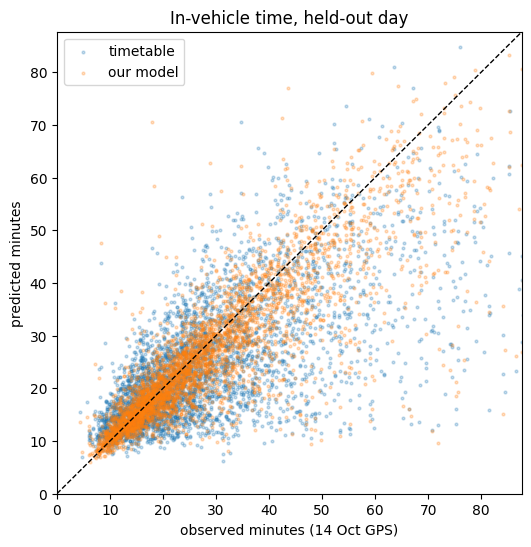

In [ ]:
DAY, DT = VALID_DAY, DAYTYPE[VALID_DAY]          # 14 Oct 2026 was a Wednesday
rng = np.random.default_rng(0)
P = prof[DT].to_dict()                           # hourly median speed, used by the distance fallback

df = pd.read_parquet(f"{CLEAN_DIR}/day_{DAY}.parquet")
tc, ts = df.trip_code.values, df.ts.values.astype("int64")
lat, lng = df.lat.values.astype("float64"), df.lng.values.astype("float64")
a0 = np.flatnonzero(np.r_[True, tc[1:] != tc[:-1]])
a1 = np.r_[a0[1:], len(tc)]

rows, nseg, nfb = [], 0, 0
for a, b in zip(a0, a1):
    k = keys_sorted[tc[a]]
    if k not in cand or b - a < 10:
        continue
    s, e, keep, j, g = best_match(k, lat[a:b], lng[a:b])
    idx = np.flatnonzero(keep)
    if len(idx) < 8:
        continue
    tp = ts[a:b][j[idx]]
    for _ in range(2):
        p = int(rng.integers(len(idx)))
        qs = np.flatnonzero((idx - idx[p] >= 8) & (idx - idx[p] <= 35))
        if len(qs) == 0:
            continue
        q = int(rng.choice(qs))
        z0, z1 = s + idx[p], s + idx[q]
        obs = tp[q] - tp[p]
        sched = st_sched[z1] - st_sched[z0]
        if obs <= 0 or obs > 7200 or sched <= 0:
            continue
        t = float(tp[p])
        for z in range(z0, z1):
            h = int(((t + IST) // 3600) % 24)
            ka, kb = st_sid[z], st_sid[z + 1]
            nseg += 1
            v = SH.get((ka, kb, DT, h))
            if v is None:
                v = SD.get((ka, kb, DT))
            if v is None:
                v = SA.get((ka, kb))
            if v is None:
                nfb += 1
                d = math.hypot((st_lon[z + 1] - st_lon[z]) * 111320 * math.cos(math.radians(28.6)),
                               (st_lat[z + 1] - st_lat[z]) * 110540) * 1.25
                v = d / (max(P[h], 8.0) / 3.6) + 10
            t += v
        rows.append((int(((tp[p] + IST) // 3600) % 24), int(idx[q] - idx[p]),
                     obs / 60, (t - tp[p]) / 60, sched / 60))
del df, tc, ts, lat, lng

r = pd.DataFrame(rows, columns=["hour", "n_stops", "obs_min", "model_min", "sched_min"])
r["bucket"] = pd.cut(r.hour, [-1, 5, 10, 16, 20, 23], labels=["00-05", "06-10", "11-16", "17-20", "21-23"])
r["model_err"] = (r.model_min - r.obs_min) / r.obs_min           # signed relative error
r["sched_err"] = (r.sched_min - r.obs_min) / r.obs_min


def summ(pred):
    e = pred - r.obs_min
    pe = (e / r.obs_min).abs()
    return pd.Series({"MAE_min": e.abs().mean(), "MedAE_min": e.abs().median(),
                      "MdAPE_%": 100 * pe.median(), "bias_%": 100 * (e / r.obs_min).median(),
                      "within20%": (pe <= 0.2).mean()})


print(f"pairs evaluated: {len(r):,} | median observed {r.obs_min.median():.1f} min | "
      f"segments predicted from distance fallback: {nfb / max(nseg, 1):.1%}")
out = pd.DataFrame({"our model": summ(r.model_min), "timetable": summ(r.sched_min)}).round(2)
print("\nAll pairs:")
print(out.to_string())

gb = r.groupby("bucket", observed=True)
print("\nBy time of day (MdAPE %, bias %):")
print(pd.DataFrame({
    "n": gb.size(),
    "model_MdAPE": 100 * gb.model_err.apply(lambda x: x.abs().median()),
    "model_bias": 100 * gb.model_err.median(),
    "timetable_MdAPE": 100 * gb.sched_err.apply(lambda x: x.abs().median()),
    "timetable_bias": 100 * gb.sched_err.median(),
}).round(1).to_string())

r.to_csv(f"{OUT_DIR}/validation_trips.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 6))
sm = r.sample(min(4000, len(r)), random_state=0)
ax.scatter(sm.obs_min, sm.sched_min, s=4, alpha=.25, label="timetable")
ax.scatter(sm.obs_min, sm.model_min, s=4, alpha=.25, label="our model")
lim = float(r.obs_min.quantile(.99))
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("observed minutes (14 Oct GPS)")
ax.set_ylabel("predicted minutes")
ax.legend()
ax.set_title("In-vehicle time, held-out day")
plt.savefig(f"{OUT_DIR}/validation_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2 End-to-end journeys against Google Maps

Ten origin-destination pairs are planned at 09:00, 14:00 and 22:30 on a Tuesday. This first table shows what the planner returns for each (fastest option).

In [ ]:
PAIRS = {
    "Kashmere Gate ISBT -> Nehru Place":   ((28.6675, 77.2282), (28.5491, 77.2512)),
    "Connaught Place -> Saket":            ((28.6315, 77.2167), (28.5245, 77.2100)),
    "Anand Vihar ISBT -> Rajouri Garden":  ((28.6469, 77.3159), (28.6492, 77.1219)),
    "Lajpat Nagar -> Karol Bagh":          ((28.5700, 77.2430), (28.6516, 77.1900)),
    "Rohini West -> Connaught Place":      ((28.7149, 77.1156), (28.6315, 77.2167)),
    "Hauz Khas -> Mayur Vihar Ph1":        ((28.5494, 77.2001), (28.6040, 77.2940)),
    "Azadpur -> ITO":                      ((28.7071, 77.1749), (28.6286, 77.2410)),
    "Munirka -> Kalkaji":                  ((28.5570, 77.1730), (28.5390, 77.2590)),
    "Red Fort -> Lajpat Nagar":            ((28.6562, 77.2410), (28.5700, 77.2430)),
    "Sarai Kale Khan -> Dilshad Garden":   ((28.5880, 77.2580), (28.6760, 77.3210)),
}
DEPARTURES = ("09:00", "14:00", "22:30")

rows = []
for name, (o, d) in PAIRS.items():
    for dep in DEPARTURES:
        res = plan(o[0], o[1], d[0], d[1], depart=dep, day="tue")
        if "error" in res:
            rows.append(dict(pair=name, depart=dep, our_min=None, transfers=None, routes=res["error"]))
            continue
        b = res["options"][0]
        rows.append(dict(pair=name, depart=dep, our_min=b["total_min"], transfers=b["transfers"],
                         routes=" > ".join(l["route"] for l in b["legs"] if l["type"] == "bus")))
gm = pd.DataFrame(rows)
print(gm.to_string())

                                  pair depart  our_min  transfers                                    routes
0    Kashmere Gate ISBT -> Nehru Place  09:00     68.3          0                                   425CLUP
1    Kashmere Gate ISBT -> Nehru Place  14:00     74.4          1                           214DOWN > 425UP
2    Kashmere Gate ISBT -> Nehru Place  22:30     60.5          0                                     425UP
3             Connaught Place -> Saket  09:00     85.7          3         359UP > 966DOWN > 502UP > 534DOWN
4             Connaught Place -> Saket  14:00     94.2          1                             620UP > 546UP
5             Connaught Place -> Saket  22:30     80.1          1                             620UP > 546UP
6   Anand Vihar ISBT -> Rajouri Garden  09:00    110.5          1                        236EXTUP > 832DOWN
7   Anand Vihar ISBT -> Rajouri Garden  14:00    124.7          2            221DOWN > 211DOWN > TMS(-)DOWN
8   Anand Vihar ISBT -> Rajo

Bus-only travel times from Google Maps were recorded by hand for 12 of these 30 pair-and-departure combinations; the others have no recorded value and are left out. They are compared with the planner's fastest option, which includes walking and waiting.

In [ ]:
# Minutes shown by Google Maps for the same pair and departure time (recorded manually)
GOOGLE_BUS_MIN = {
    ("Kashmere Gate ISBT -> Nehru Place", "09:00"): 80,
    ("Kashmere Gate ISBT -> Nehru Place", "22:30"): 80,
    ("Connaught Place -> Saket", "09:00"): 104,
    ("Anand Vihar ISBT -> Rajouri Garden", "09:00"): 117,
    ("Lajpat Nagar -> Karol Bagh", "09:00"): 49,
    ("Rohini West -> Connaught Place", "09:00"): 74,
    ("Rohini West -> Connaught Place", "22:30"): 81,
    ("Hauz Khas -> Mayur Vihar Ph1", "09:00"): 68,
    ("Azadpur -> ITO", "09:00"): 67,
    ("Azadpur -> ITO", "22:30"): 88,
    ("Munirka -> Kalkaji", "09:00"): 56,
    ("Red Fort -> Lajpat Nagar", "09:00"): 44,
}

gm["google_bus_min"] = [GOOGLE_BUS_MIN.get((p, d)) for p, d in zip(gm.pair, gm.depart)]
gm["abs_err_min"] = (gm.our_min - gm.google_bus_min).abs()
gm["err_%"] = 100 * (gm.our_min - gm.google_bus_min) / gm.google_bus_min
gm.to_csv(f"{OUT_DIR}/google_comparison.csv", index=False)

d2 = gm.dropna(subset=["google_bus_min"])
print(d2[["pair", "depart", "our_min", "google_bus_min", "abs_err_min", "err_%"]].round(1).to_string())
print("pairs:", len(d2), "| MAE:", round(d2.abs_err_min.mean(), 1), "| MdAPE:", round(d2["err_%"].abs().median(), 1),
      "| bias:", round(d2["err_%"].median(), 1), "| within20:", round((d2["err_%"].abs() <= 20).mean(), 2))

                                  pair depart  our_min  google_bus_min  abs_err_min  err_%
0    Kashmere Gate ISBT -> Nehru Place  09:00     68.3            80.0         11.7  -14.6
2    Kashmere Gate ISBT -> Nehru Place  22:30     60.5            80.0         19.5  -24.4
3             Connaught Place -> Saket  09:00     85.7           104.0         18.3  -17.6
6   Anand Vihar ISBT -> Rajouri Garden  09:00    110.5           117.0          6.5   -5.6
9           Lajpat Nagar -> Karol Bagh  09:00     78.0            49.0         29.0   59.2
12      Rohini West -> Connaught Place  09:00     94.3            74.0         20.3   27.4
14      Rohini West -> Connaught Place  22:30     72.0            81.0          9.0  -11.1
15        Hauz Khas -> Mayur Vihar Ph1  09:00     89.8            68.0         21.8   32.1
18                      Azadpur -> ITO  09:00     63.9            67.0          3.1   -4.6
20                      Azadpur -> ITO  22:30     53.9            88.0         34.1  -38.8

## 8. REST API and map page

The planner is wrapped in a small FastAPI service:

| endpoint | purpose |
|---|---|
| `GET /journeys?from=&to=&depart=HH:MM&day=mon..sun` | up to two journey options. `from` and `to` are either `lat,lng` or a stop name |
| `GET /stops?q=` | search stops by name |
| `GET /health` | service status |
| `GET /` | map page: click an origin and a destination |
| `GET /docs` | interactive API documentation |

In [ ]:
import nest_asyncio, uvicorn
from fastapi import FastAPI, Query
from fastapi.responses import JSONResponse, HTMLResponse
from fastapi.middleware.cors import CORSMiddleware
nest_asyncio.apply()

app = FastAPI(title="Delhi Bus Journey Planner",
              description="Bus journeys with travel times learned from October 2026 DTC GPS data.")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

names_l = [n.lower() for n in sname]


def resolve(q):
    """'lat,lng' -> coordinates; otherwise the busiest stop whose name contains q."""
    m = re.match(r"^\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*$", q)
    if m:
        return float(m.group(1)), float(m.group(2)), None
    ql = q.strip().lower()
    hits = [i for i, n in enumerate(names_l) if ql in n]
    if not hits:
        return None
    i = max(hits, key=lambda k: len(board[k]))          # busiest matching stop
    return float(LAT[i]), float(LON[i]), sname[i]


def bad(msg, code=400):
    return JSONResponse({"error": msg}, status_code=code)


@app.get("/health")
def health():
    return {"status": "ok", "stops": S, "route_patterns": len(pat)}


@app.get("/stops")
def find_stops(q: str, limit: int = 10):
    ql = q.lower()
    hits = [i for i, n in enumerate(names_l) if ql in n]
    hits.sort(key=lambda k: -len(board[k]))
    return [{"name": sname[i], "lat": float(LAT[i]), "lng": float(LON[i])} for i in hits[:limit]]


@app.get("/journeys")
def journeys(from_: str = Query(..., alias="from", description="'lat,lng' or a stop name"),
             to: str = Query(..., description="'lat,lng' or a stop name"),
             depart: str = Query("08:30", description="HH:MM, 24-hour, IST"),
             day: str = Query("tue", description="mon..sun")):
    if not re.match(r"^\d{1,2}:\d{2}$", depart) or int(depart.split(":")[0]) > 23 or int(depart.split(":")[1]) > 59:
        return bad("depart must be HH:MM (24-hour)")
    if day.lower()[:3] not in ("mon", "tue", "wed", "thu", "fri", "sat", "sun"):
        return bad("day must be one of mon..sun")
    o, d = resolve(from_), resolve(to)
    if o is None:
        return bad(f"could not find origin '{from_}'")
    if d is None:
        return bad(f"could not find destination '{to}'")
    for la, lo, _ in (o, d):
        if not (28.2 <= la <= 29.1 and 76.7 <= lo <= 77.8):
            return bad("coordinates are outside the Delhi area")
    res = plan(o[0], o[1], d[0], d[1], depart=depart, day=day)
    if "error" in res:
        return JSONResponse(res, status_code=404)
    res["from"] = {"lat": o[0], "lng": o[1], "stop": o[2]}
    res["to"] = {"lat": d[0], "lng": d[1], "stop": d[2]}
    return res


PAGE = r"""<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Delhi Bus Journey Planner</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<style>
 body{margin:0;font-family:system-ui,sans-serif;display:flex;height:100vh}
 #side{width:380px;padding:12px;overflow:auto;box-sizing:border-box;background:#f7f7f8}
 #map{flex:1}
 h2{margin:0 0 6px;font-size:18px} .hint{font-size:13px;color:#555;margin-bottom:8px}
 label{font-size:13px;margin-right:6px} select,input,button{font-size:14px;padding:4px;margin:2px 0}
 .opt{background:#fff;border:2px solid #ddd;border-radius:8px;padding:8px;margin:8px 0;cursor:pointer}
 .opt.sel{border-color:#2a6df4} .tot{font-weight:600} .small{font-size:12px;color:#555}
 .leg{font-size:13px;margin:2px 0}
 @media(max-width:700px){body{flex-direction:column-reverse}#side{width:100%;height:45vh}}
</style></head><body>
<div id="side">
 <h2>Delhi bus journey planner</h2>
 <div class="hint">Click the map to set the <b>origin</b>, then the <b>destination</b>. Click again to restart.</div>
 <div><label>Day</label><select id="day"><option value="mon">Mon</option><option value="tue" selected>Tue</option>
  <option value="wed">Wed</option><option value="thu">Thu</option><option value="fri">Fri</option>
  <option value="sat">Sat</option><option value="sun">Sun</option></select>
 <label>Depart</label><input id="dep" type="time" value="08:30"> <button id="go">Plan</button> <button id="reset">Reset</button></div>
 <div id="status" class="small"></div><div id="res"></div>
 <div class="small">Times are learned from Oct 2026 DTC bus GPS. Buses only; walking and waiting included.</div>
</div><div id="map"></div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<script>
const map=L.map('map').setView([28.6139,77.2090],11);
L.tileLayer('https://tile.openstreetmap.org/{z}/{x}/{y}.png',{maxZoom:19,attribution:'&copy; OpenStreetMap'}).addTo(map);
let O=null,D=null,mO=null,mD=null,layer=L.layerGroup().addTo(map),data=null;
const COLORS=['#d62728','#1f77b4','#2ca02c','#9467bd'];
function status(t){document.getElementById('status').textContent=t}
function reset(){O=D=null;[mO,mD].forEach(m=>m&&map.removeLayer(m));mO=mD=null;layer.clearLayers();
 document.getElementById('res').innerHTML='';status('')}
map.on('click',e=>{
 if(O&&D)reset();
 if(!O){O=e.latlng;mO=L.marker(O).addTo(map).bindTooltip('Origin');status('Now click the destination')}
 else{D=e.latlng;mD=L.marker(D).addTo(map).bindTooltip('Destination');plan()}});
document.getElementById('reset').onclick=reset;
document.getElementById('go').onclick=()=>{if(O&&D)plan();else status('Click origin and destination first')};
async function plan(){
 status('Planning...');document.getElementById('res').innerHTML='';layer.clearLayers();
 const q=new URLSearchParams({from:O.lat+','+O.lng,to:D.lat+','+D.lng,
  depart:document.getElementById('dep').value,day:document.getElementById('day').value});
 try{const r=await fetch('journeys?'+q);data=await r.json();
  if(!r.ok||data.error){status(data.error||'Request failed');return}
  status('');show()}catch(e){status('Could not reach the API')}}
function show(){
 const box=document.getElementById('res');box.innerHTML='';
 data.options.forEach((o,i)=>{
  const d=document.createElement('div');d.className='opt';
  const q=Object.keys(o).find(k=>k.startsWith('best_route_minutes_at_'));
  const h=document.createElement('div');h.className='tot';
  h.textContent=o.total_min+' min, '+o.transfers+' transfer(s), arrive '+o.arrive;d.appendChild(h);
  o.legs.forEach(l=>{const p=document.createElement('div');p.className='leg';
   p.textContent=l.type==='walk'?('Walk '+l.min+' min to '+l.to):
    ('Bus '+l.route+': '+l.board+' -> '+l.alight+' ('+l.stops+' stops, wait ~'+l.wait_min+' min, ride '+l.ride_min+' min)');
   d.appendChild(p)});
  if(o[q]!=null){const s=document.createElement('div');s.className='small';
   s.textContent='Same trip planned at '+q.split('_at_')[1]+': '+o[q]+' min';d.appendChild(s)}
  d.onclick=()=>draw(i);box.appendChild(d)});
 draw(0)}
function draw(i){
 layer.clearLayers();
 [...document.querySelectorAll('.opt')].forEach((e,j)=>e.classList.toggle('sel',j===i));
 const o=data.options[i];let c=0;
 o.legs.forEach(l=>{if(l.type==='bus'&&l.board_ll&&l.alight_ll){
  const col=COLORS[c++%COLORS.length];
  L.polyline([l.board_ll,l.alight_ll],{color:col,weight:5}).addTo(layer).bindTooltip('Bus '+l.route);
  L.circleMarker(l.board_ll,{radius:5,color:col}).addTo(layer);
  L.circleMarker(l.alight_ll,{radius:5,color:col,fill:true}).addTo(layer)}})}
</script></body></html>"""

@app.get("/", response_class=HTMLResponse, include_in_schema=False)
def home():
    return PAGE


server = uvicorn.Server(uvicorn.Config(app, host="0.0.0.0", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
time.sleep(3)

# quick local checks
print(requests.get("http://127.0.0.1:8000/health").json())
r = requests.get("http://127.0.0.1:8000/journeys",
                 params={"from": "28.6675,77.2282", "to": "28.5491,77.2512", "depart": "08:30", "day": "tue"})
print(r.status_code, [(o["total_min"], o["transfers"]) for o in r.json()["options"]])
print(requests.get("http://127.0.0.1:8000/stops", params={"q": "nehru place"}).json()[:2])

{'status': 'ok', 'stops': 6862, 'route_patterns': 3357}
200 [(67.0, 0)]
[{'name': 'Nehru Place Terminal', 'lat': 28.54870017781327, 'lng': 77.25698123406022}, {'name': 'Nehru Place', 'lat': 28.54755, 'lng': 77.249444}]


### Public link

A Cloudflare quick tunnel exposes the local API on a temporary public URL. The link works only while this Colab runtime stays alive, and a new URL is issued every time the cell is run.

In [ ]:
if not os.path.exists("/content/cloudflared"):
    subprocess.run("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 "
                   "-O /content/cloudflared && chmod +x /content/cloudflared", shell=True, check=True)

log = open("/content/cf.log", "w")
subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://127.0.0.1:8000"], stdout=log, stderr=log)

url = None
for _ in range(40):
    time.sleep(1)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("/content/cf.log").read())
    if m:
        url = m.group(0)
        break

print("Public URL:", url)
if url:
    print("Map page  :", url + "/")
    print("API docs  :", url + "/docs")
    print("Example   :", url + "/journeys?from=28.6675,77.2282&to=28.5491,77.2512&depart=08:30&day=tue")
else:
    print(open("/content/cf.log").read()[-800:])

Public URL: https://towns-elect-holiday-serve.trycloudflare.com
Map page  : https://towns-elect-holiday-serve.trycloudflare.com/
API docs  : https://towns-elect-holiday-serve.trycloudflare.com/docs
Example   : https://towns-elect-holiday-serve.trycloudflare.com/journeys?from=28.6675,77.2282&to=28.5491,77.2512&depart=08:30&day=tue


### Example API responses and deliverables

Three sample responses are saved as JSON next to the validation table, the validation scatter plot and the Google comparison, and zipped into `final_outputs.zip`.

In [ ]:
samples = [("28.6675,77.2282", "28.5491,77.2512", "08:30", "tue"),
           ("28.6675,77.2282", "28.5491,77.2512", "23:00", "tue"),
           ("28.7149,77.1156", "28.6315,77.2167", "09:00", "wed")]

paths = []
for i, (a, b, d, day) in enumerate(samples):
    r = requests.get("http://localhost:8000/journeys",
                     params={"from": a, "to": b, "depart": d, "day": day}, timeout=90)
    p = f"{OUT_DIR}/sample_{i}.json"
    with open(p, "w") as f:
        json.dump(r.json(), f, indent=1)
    paths.append(p)
    o = r.json().get("options", [{}])[0]
    print(i, r.status_code, o.get("total_min"), o.get("transfers"), [l.get("route") for l in o.get("legs", []) if l["type"] == "bus"])

extra = [f"{OUT_DIR}/validation_trips.csv", f"{OUT_DIR}/validation_scatter.png", f"{OUT_DIR}/google_comparison.csv"]
with zipfile.ZipFile(f"{OUT_DIR}/final_outputs.zip", "w") as z:
    for p in paths + extra:
        z.write(p, os.path.basename(p))

0 200 67.0 0 ['425CLUP']
1 200 60.3 0 ['449UP']
2 200 94.3 1 ['984ADOWN', 'DS-8DOWN']


In [ ]:
# Optional (Colab): download the deliverables to your computer
from google.colab import files
files.download(f"{OUT_DIR}/final_outputs.zip")

## 9. Results and limitations

**In-vehicle time on the held-out day (30,306 stop pairs).** The learned model beats the timetable on every measure reported: MAE 5.3 vs 8.6 min, median absolute percentage error 11.7% vs 23.9%, and 71% vs 43% of pairs within 20% of the observed time. The timetable is especially poor at night (00-05: MdAPE 48%) and in the evening peak (17-20: bias -27%). The model's own error is largest in the evening peak (MdAPE 14.6%, bias -8.9%).

**End-to-end journeys against Google Maps (12 comparisons).** MAE 17.6 min, MdAPE 21.2%, median bias -8.3%, and 50% of journeys within 20%. Individual errors range from about -39% to +64%, so the end-to-end planner is considerably less accurate than the in-vehicle model.

**Limitations**
- **Little training data.** Only 4 of 31 days were used: two weekdays and one Sunday for fitting, one weekday for validation. The weekend model rests on a single day.
- **Only linkable trips.** About half of the GPS trips (the 3-part IDs) can be tied to scheduled stops; the rest are ignored. In the segment extraction a bus is credited with only about 51-58% of its scheduled stops, because a ping must fall within 120 m of the stop.
- **Waiting time is a schedule-based estimate**, not observed headways. It is the weakest part of the end-to-end estimate. It depends on the scheduled trip counts per route and hour and on an assumed 18-hour service day.
- **Validation covers in-vehicle time only.** It does not test walking, waiting or transfers. It also uses the plain lookup (hourly, then day-type, then any-hour median, then distance), without the hour-of-day speed rescaling the planner applies to the day-type and any-hour medians, so it is a close but not identical test of the planner's ride times.
- **The Google Maps comparison is small and manual** (12 values collected by hand); the date and time basis of those values is not recorded in this notebook.
- **The Google Maps comparison is not an independent test.** The waiting-time scaling was adjusted and the comparison re-run on the same values, so it can look better than it would on fresh journeys.
- **Map lines are straight** between the boarding and alighting stop of each bus leg; the GTFS `shapes.txt` road geometry is not used.
- **Public link is temporary.** It disappears when the Colab runtime stops.